In [10]:
import os
import zipfile

# --- 1. ตั้งค่า Path สำหรับ API Key ---
# วางไฟล์ kaggle.json ไว้ในที่ที่ระบบเรียกถึงได้
os.environ['KAGGLE_CONFIG_DIR'] = "/content/" 

def download_sleep_data():
    comp_id = "super-ai-engineer-ss-6-sleep-stage-classification"
    
    # --- 2. สั่งดาวน์โหลด ---
    print(f"กำลังเริ่มดาวน์โหลดข้อมูลจาก: {comp_id}")
    os.system(f"kaggle competitions download -c {comp_id}")
    
    # --- 3. การจัดการไฟล์ Zip ---
    zip_name = f"{comp_id}.zip"
    if os.path.exists(zip_name):
        print(f"พบไฟล์ {zip_name} กำลังแตกไฟล์...")
        with zipfile.ZipFile(zip_name, 'r') as zip_ref:
            # แตกไฟล์ไปที่โฟลเดอร์ 'sleep_data'
            zip_ref.extractall("sleep_data")
        
        # ลบไฟล์ Zip เพื่อคืนพื้นที่ Disk (สำคัญมากเพราะข้อมูลใหญ่ถึง 5.45 GB)
        os.remove(zip_name)
        print("ดาวน์โหลดและแตกไฟล์สำเร็จ! ข้อมูลอยู่ในโฟลเดอร์ 'sleep_data/'")
    else:
        print("เกิดข้อผิดพลาด: ไม่พบไฟล์ดาวน์โหลด โปรดตรวจสอบไฟล์ kaggle.json")

# รันฟังก์ชัน
download_sleep_data()

กำลังเริ่มดาวน์โหลดข้อมูลจาก: super-ai-engineer-ss-6-sleep-stage-classification


100%|██████████| 2.13G/2.13G [00:08<00:00, 264MB/s]



พบไฟล์ super-ai-engineer-ss-6-sleep-stage-classification.zip กำลังแตกไฟล์...
ดาวน์โหลดและแตกไฟล์สำเร็จ! ข้อมูลอยู่ในโฟลเดอร์ 'sleep_data/'


In [11]:
import pandas as pd
import numpy as np
import os
from tqdm import tqdm
from scipy.stats import skew, kurtosis
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

In [12]:

test_df = pd.read_csv('/kaggle/working/sleep_data/train/train/train001.csv')
print(test_df.columns)

Index(['BVP', 'ACC_X', 'ACC_Y', 'ACC_Z', 'TEMP', 'EDA', 'HR', 'IBI',
       'Sleep_Stage'],
      dtype='object')


In [13]:
# --- 1. ปรับฟังก์ชันดึง Feature ให้ข้ามคอลัมน์ Sleep_Stage ---
def extract_signal_features(df):
    feat = {}
    # เลือกเฉพาะคอลัมน์ตัวเลข และไม่ใช่คอลัมน์เฉลย
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    cols_to_use = [c for c in numeric_cols if c != 'Sleep_Stage']
    
    for col in cols_to_use:
        sig = df[col].values
        
        # Pre-processing: เติมค่าว่างถ้ามี
        if np.isnan(sig).any():
            sig = pd.Series(sig).interpolate().fillna(method='bfill').values
            
        # สกัดฟีเจอร์สถิติ (Time-domain)
        feat[f'{col}_mean'] = np.mean(sig)
        feat[f'{col}_std']  = np.std(sig)
        feat[f'{col}_min']  = np.min(sig)
        feat[f'{col}_max']  = np.max(sig)
        # สถิติขั้นสูง (อาจมี Warning ถ้าสัญญาณนิ่งเกินไป แต่รันต่อได้)
        feat[f'{col}_skew'] = skew(sig)
        feat[f'{col}_kurt'] = kurtosis(sig)
        
    return feat

# --- 2. ดึงข้อมูลจากทุกไฟล์ (Aggregation) ---
all_features = []
file_list = [f for f in os.listdir('/kaggle/working/sleep_data/train/train') if f.endswith('.csv')]

for filename in tqdm(file_list):
    df = pd.read_csv(os.path.join('/kaggle/working/sleep_data/train/train', filename))
    
    features = extract_signal_features(df)
    features['file_id'] = filename
    
    # ดึงเฉลยจากคอลัมน์ Sleep_Stage
    if 'Sleep_Stage' in df.columns:
        features['target'] = df['Sleep_Stage'].iloc[0]
        
    all_features.append(features)

train_df = pd.DataFrame(all_features)

# --- 3. แยก X และ y เพื่อ Train ---
# เราจะลบ 'target' (เฉลย) และ 'file_id' (ชื่อไฟล์) ออกจาก X
X = train_df.drop(columns=['target', 'file_id'], errors='ignore')
y = train_df['target']

print(f"เตรียมข้อมูลเสร็จแล้ว! ขนาดของ X: {X.shape}")

  8%|▊         | 7/83 [00:04<00:52,  1.44it/s]/tmp/ipykernel_55/2764700113.py:21: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  feat[f'{col}_skew'] = skew(sig)
/tmp/ipykernel_55/2764700113.py:22: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  feat[f'{col}_kurt'] = kurtosis(sig)
 52%|█████▏    | 43/83 [00:29<00:26,  1.54it/s]/tmp/ipykernel_55/2764700113.py:21: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  feat[f'{col}_skew'] = skew(sig)
/tmp/ipykernel_55/2764700113.py:22: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. 

เตรียมข้อมูลเสร็จแล้ว! ขนาดของ X: (83, 48)


In [14]:

# 3.3 Model Training
print("กำลังฝึกสอนโมเดล...")
model = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
model.fit(X, y)

print("Training สำเร็จ!")

กำลังฝึกสอนโมเดล...
Training สำเร็จ!


In [ ]:
import pandas as pd
import os
from tqdm import tqdm

# --- 1. กำหนด Path หลักของ Test Segment ---
base_test_path = '/kaggle/working/sleep_data/test_segment/test_segment'
submission_df = pd.read_csv('/kaggle/working/sleep_data/sample_submission.csv')

test_features = []

print("กำลังเริ่มประมวลผลไฟล์ Test ตามโครงสร้างโฟลเดอร์...")

for segment_id in tqdm(submission_df['id']):
    # segment_id มักจะมาในรูปแบบ 'test001_00000'
    # เราต้องแยก 'test001' ออกมาเพื่อระบุชื่อโฟลเดอร์ย่อย
    sub_folder = segment_id.split('_')[0] 
    
    # สร้าง Path เต็ม: base / test001 / test001_00000.csv
    filepath = os.path.join(base_test_path, sub_folder, f"{segment_id}.csv")
    
    if os.path.exists(filepath):
        # อ่านไฟล์และสกัดฟีเจอร์ด้วยฟังก์ชันเดิม
        test_df = pd.read_csv(filepath)
        feat = extract_signal_features(test_df)
        feat['id'] = segment_id
        test_features.append(feat)
    else:
        # กรณีหาไม่เจอ ให้ลองหาแบบไม่มีโฟลเดอร์ย่อย (เผื่อไว้)
        alt_path = os.path.join(base_test_path, f"{segment_id}.csv")
        if os.path.exists(alt_path):
            test_df = pd.read_csv(alt_path)
            feat = extract_signal_features(test_df)
            feat['id'] = segment_id
            test_features.append(feat)
        else:
            print(f"\n⚠️ ไม่พบไฟล์: {segment_id} ที่ Path: {filepath}")

# แปลงเป็น DataFrame พร้อมทำนาย
X_test_final = pd.DataFrame(test_features)

กำลังเริ่มประมวลผลไฟล์ Test ตามโครงสร้างโฟลเดอร์...


  0%|          | 7/7832 [00:00<02:06, 61.75it/s]/tmp/ipykernel_55/2764700113.py:21: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  feat[f'{col}_skew'] = skew(sig)
/tmp/ipykernel_55/2764700113.py:22: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  feat[f'{col}_kurt'] = kurtosis(sig)
  0%|          | 14/7832 [00:00<02:01, 64.42it/s]/tmp/ipykernel_55/2764700113.py:21: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  feat[f'{col}_skew'] = skew(sig)
/tmp/ipykernel_55/2764700113.py:22: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identic

In [ ]:
import pandas as pd
import os
from tqdm import tqdm

# --- 1. กำหนด Path หลักของ Test Segment ---
base_test_path = '/kaggle/working/sleep_data/test_segment/test_segment'
submission_df = pd.read_csv('/kaggle/working/sleep_data/sample_submission.csv')

test_features = []

print("กำลังเริ่มประมวลผลไฟล์ Test ตามโครงสร้างโฟลเดอร์...")

for segment_id in tqdm(submission_df['id']):
    # segment_id มักจะมาในรูปแบบ 'test001_00000'
    # เราต้องแยก 'test001' ออกมาเพื่อระบุชื่อโฟลเดอร์ย่อย
    sub_folder = segment_id.split('_')[0] 
    
    # สร้าง Path เต็ม: base / test001 / test001_00000.csv
    filepath = os.path.join(base_test_path, sub_folder, f"{segment_id}.csv")
    
    if os.path.exists(filepath):
        # อ่านไฟล์และสกัดฟีเจอร์ด้วยฟังก์ชันเดิม
        test_df = pd.read_csv(filepath)
        feat = extract_signal_features(test_df)
        feat['id'] = segment_id
        test_features.append(feat)
    else:
        # กรณีหาไม่เจอ ให้ลองหาแบบไม่มีโฟลเดอร์ย่อย (เผื่อไว้)
        alt_path = os.path.join(base_test_path, f"{segment_id}.csv")
        if os.path.exists(alt_path):
            test_df = pd.read_csv(alt_path)
            feat = extract_signal_features(test_df)
            feat['id'] = segment_id
            test_features.append(feat)
        else:
            print(f"\n⚠️ ไม่พบไฟล์: {segment_id} ที่ Path: {filepath}")

# แปลงเป็น DataFrame พร้อมทำนาย
X_test_final = pd.DataFrame(test_features)

กำลังเริ่มประมวลผลไฟล์ Test ตามโครงสร้างโฟลเดอร์...


  0%|          | 7/7832 [00:00<01:59, 65.66it/s]/tmp/ipykernel_55/2764700113.py:21: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  feat[f'{col}_skew'] = skew(sig)
/tmp/ipykernel_55/2764700113.py:22: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  feat[f'{col}_kurt'] = kurtosis(sig)
  0%|          | 14/7832 [00:00<01:59, 65.49it/s]/tmp/ipykernel_55/2764700113.py:21: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  feat[f'{col}_skew'] = skew(sig)
/tmp/ipykernel_55/2764700113.py:22: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identic

random forest ตอบแต่ w

In [28]:
# --- 1. ตรวจสอบลำดับข้อมูล (Data Alignment) ---
# เพื่อความชัวร์ เราจะ Merge ข้อมูลที่สกัดได้ กลับเข้าหาลำดับใน sample_submission
final_test_df = pd.merge(submission_df[['id']], X_test_final, on='id', how='left')

# เช็คว่ามีค่าว่างหลุดมาไหม (ถ้าหาไฟล์บางไฟล์ไม่เจอ)
if final_test_df.isna().any().any():
    print("⚠️ คำเตือน: มีบางไฟล์ที่หาไม่เจอและเป็นค่า NaN กำลังเติมด้วยค่าเฉลี่ย...")
    final_test_df = final_test_df.fillna(X.mean()) # เติมด้วยค่าเฉลี่ยจากชุด Train

# --- 2. ตัดคอลัมน์ ID ออกเพื่อเตรียมเข้าโมเดล ---
X_test_ready = final_test_df.drop(columns=['id'])

# --- 3. ทำนายผล (Inference) ---
print("กำลังทำนายผลด้วย Random Forest...")
y_test_pred = model.predict(X_test_ready)

# --- 4. สร้างไฟล์ Submission ---
submission_df['labels'] = y_test_pred

# บันทึกไฟล์ CSV (ห้ามมี Index)
submission_filename = 'submission_chuji.csv'
submission_df.to_csv(submission_filename, index=False)

print(f"✅ เสร็จสมบูรณ์! สร้างไฟล์ {submission_filename} เรียบร้อย")
print(submission_df.head())

⚠️ คำเตือน: มีบางไฟล์ที่หาไม่เจอและเป็นค่า NaN กำลังเติมด้วยค่าเฉลี่ย...
กำลังทำนายผลด้วย Random Forest...
✅ เสร็จสมบูรณ์! สร้างไฟล์ submission_chuji.csv เรียบร้อย
              id labels
0  test001_00000      W
1  test001_00001      W
2  test001_00002      W
3  test001_00003      W
4  test001_00004      W


In [20]:
print(submission_df['labels'].value_counts())

labels
W    7832
Name: count, dtype: int64


In [33]:
# ดูว่ามี Stage อะไรบ้าง และมีอย่างละกี่แถว
print("จำนวนข้อมูลในแต่ละ Sleep Stage:")
print(train_df['target'].value_counts())

# ถ้ารายชื่อ Stage ออกมาไม่ครบ 5 คลาส แสดงว่าตอนวนลูปอ่านไฟล์ เราอาจจะอ่านไม่ครบทุกโฟลเดอร์ครับ

จำนวนข้อมูลในแต่ละ Sleep Stage:
target
W     81
N2     1
N1     1
Name: count, dtype: int64


In [29]:
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

# --- 1. แปลง Label ตัวอักษรให้เป็นตัวเลข (Encoding) ---
le = LabelEncoder()
# y คือคอลัมน์ 'target' ที่เราดึงมาจาก Sleep_Stage ตอนแรก
y_encoded = le.fit_transform(y)

# ดูว่าเลขไหนคู่กับ Stage ไหน (เก็บไว้เช็ค)
mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print(f"Mapping ของเราคือ: {mapping}")

# --- 2. สร้างและฝึกสอนโมเดล XGBoost ---
print("กำลังฝึกสอน XGBoost...")
model_xgb = XGBClassifier(
    n_estimators=200, 
    learning_rate=0.05, 
    max_depth=6, 
    random_state=42,
    tree_method='hist' # ช่วยให้ประมวลผลเร็วขึ้นสำหรับข้อมูลเยอะๆ
)

model_xgb.fit(X, y_encoded)
print("Training XGBoost สำเร็จ!")

# --- 3. ตอนทำนายผล (Prediction) ---
# ทำนายออกมาจะได้เป็นตัวเลข (0, 1, 2...)
y_pred_numeric = model_xgb.predict(X_test_ready)

# ต้องแปลงตัวเลขกลับเป็นตัวอักษร (W, N1, N2...) ก่อนใส่ Submission
y_pred_final = le.inverse_transform(y_pred_numeric)

# ใส่ลงใน Submission
submission_df['labels'] = y_pred_final
submission_df.to_csv('submission_xgb_chuji.csv', index=False)
print("สร้างไฟล์ด้วย XGBoost สำเร็จ!")

Mapping ของเราคือ: {'N1': np.int64(0), 'N2': np.int64(1), 'W': np.int64(2)}
กำลังฝึกสอน XGBoost...
Training XGBoost สำเร็จ!
สร้างไฟล์ด้วย XGBoost สำเร็จ!


In [32]:
# --- 1. เตรียมข้อมูล Test ให้พร้อม (ยึดตามลำดับใน sample_submission) ---
# มั่นใจว่า X_test_final ของเรามีคอลัมน์เหมือนกับ X ตอน Train เป๊ะๆ
final_test_df = pd.merge(submission_df[['id']], X_test_final, on='id', how='left')

# เติมค่าว่าง (ถ้ามีไฟล์ไหนหาไม่เจอ) ด้วยค่าเฉลี่ยจากชุด Train
X_test_ready = final_test_df.drop(columns=['id']).fillna(X.mean())

# --- 2. ทำนายผลเป็นตัวเลข (0, 1, 2) ---
print("กำลังทำนายผลด้วย XGBoost...")
y_test_pred_numeric = model_xgb.predict(X_test_ready)

# --- 3. แปลงตัวเลขกลับเป็นตัวอักษร (Inverse Transform) ---
# le คือ LabelEncoder ที่เราใช้ตอน fit(y) ก่อนหน้านี้
y_test_pred_labels = le.inverse_transform(y_test_pred_numeric)

# --- 4. สร้างไฟล์ CSV เพื่อส่ง Kaggle ---
submission_df['labels'] = y_test_pred_labels
submission_filename = 'submission_xgb_chuji_final.csv'
submission_df.to_csv(submission_filename, index=False)

print(f"✅ สร้างไฟล์สำเร็จ: {submission_filename}")
print(submission_df.head())

กำลังทำนายผลด้วย XGBoost...
✅ สร้างไฟล์สำเร็จ: submission_xgb_chuji_final.csv
              id labels
0  test001_00000     N1
1  test001_00001     N1
2  test001_00002     N1
3  test001_00003     N1
4  test001_00004     N1


ทำ segment

In [34]:
def extract_signal_features(df):
    """สกัดฟีเจอร์สถิติ (โค้ดเดิม)"""
    feat = {}
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    cols_to_use = [c for c in numeric_cols if c != 'Sleep_Stage']
    
    for col in cols_to_use:
        sig = df[col].values
        if np.isnan(sig).any():
            sig = pd.Series(sig).interpolate().fillna(method='bfill').fillna(0).values
            
        feat[f'{col}_mean'] = np.mean(sig)
        feat[f'{col}_std']  = np.std(sig)
        feat[f'{col}_min']  = np.min(sig)
        feat[f'{col}_max']  = np.max(sig)
    return feat

def build_master_table_chunked(folder_path):
    all_features = []
    file_list = [f for f in os.listdir(folder_path) if f.endswith('.csv')]
    
    # กำหนดขนาดของ Window: 16 Hz * 30 วินาที = 480 แถว
    chunk_size = 480 
    
    print(f"กำลังประมวลผลไฟล์และแบ่งช่วง 30 วินาที (Segmentation)...")
    for filename in tqdm(file_list):
        filepath = os.path.join(folder_path, filename)
        df = pd.read_csv(filepath)
        
        # วนลูปหั่นข้อมูลทีละ 480 แถว
        for start_idx in range(0, len(df), chunk_size):
            chunk = df.iloc[start_idx : start_idx + chunk_size]
            
            # ป้องกัน Error: ถ้าข้อมูลท่อนสุดท้ายไม่ครบ 30 วินาที ให้ทิ้งไป
            if len(chunk) < chunk_size:
                continue
                
            # 1. สกัดฟีเจอร์จากท่อน 30 วินาทีนี้
            features = extract_signal_features(chunk)
            
            # 2. หาเฉลยของท่อนนี้ (เลือกค่าที่โผล่มาบ่อยที่สุดใน 480 แถวนี้)
            if 'Sleep_Stage' in chunk.columns:
                features['target'] = chunk['Sleep_Stage'].mode()[0]
                
            all_features.append(features)
            
    return pd.DataFrame(all_features)

# --- เรียกใช้งาน ---
train_df = build_master_table_chunked('/kaggle/working/sleep_data/train/train')

print("จำนวนข้อมูลในแต่ละ Sleep Stage หลังจากแบ่งช่วงแล้ว:")
print(train_df['target'].value_counts())

กำลังประมวลผลไฟล์และแบ่งช่วง 30 วินาที (Segmentation)...


100%|██████████| 83/83 [02:16<00:00,  1.65s/it]


จำนวนข้อมูลในแต่ละ Sleep Stage หลังจากแบ่งช่วงแล้ว:
target
N2    33786
W     15828
N1     7753
R      7033
N3     2345
Name: count, dtype: int64


In [36]:
# --- 1. บังคับให้ชุด Test มีคอลัมน์เท่ากับชุด Train เป๊ะๆ ---
# X คือตัวแปรชุด Train ที่มี 32 คอลัมน์
X_test_ready = X_test_ready[X.columns]

print(f"ปรับขนาด X_test สำเร็จ! ตอนนี้มี {X_test_ready.shape[1]} คอลัมน์ (เท่ากับ Train แล้ว)")

# --- 2. ทำนายผลชุด Test ใหม่อีกครั้ง ---
print("กำลังทำนายผลด้วย XGBoost...")
y_test_pred_numeric = model_xgb.predict(X_test_ready)

# --- 3. แปลงตัวเลขกลับเป็นตัวอักษร ---
# (0, 1, 2, 3, 4 -> N1, N2, N3, R, W)
y_test_pred_labels = le.inverse_transform(y_test_pred_numeric)

# --- 4. บันทึกไฟล์ส่ง Kaggle ---
submission_df['labels'] = y_test_pred_labels
submission_filename = 'submission_xgb_chuji_5classes_fixed.csv'
submission_df.to_csv(submission_filename, index=False)

print(f"✅ กู้ชีพสำเร็จ! สร้างไฟล์ {submission_filename} พร้อมส่งแล้วครับ")

ปรับขนาด X_test สำเร็จ! ตอนนี้มี 32 คอลัมน์ (เท่ากับ Train แล้ว)
กำลังทำนายผลด้วย XGBoost...
✅ กู้ชีพสำเร็จ! สร้างไฟล์ submission_xgb_chuji_5classes_fixed.csv พร้อมส่งแล้วครับ


In [37]:
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

# --- 1. เตรียม X และ y ---
X = train_df.drop(columns=['target', 'file_id'], errors='ignore')
y = train_df['target']

# --- 2. กระบวนการ Encoding (W, N1, N2, N3, R -> 0, 1, 2, 3, 4) ---
le = LabelEncoder()
y_encoded = le.fit_transform(y)
print(f"Mapping ทั้ง 5 คลาส: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# --- 3. กระบวนการถ่วงน้ำหนัก (Handling Imbalance) ---
print("กำลังคำนวณน้ำหนักเพื่อชดเชยคลาส N3 และ R ที่มีน้อย...")
weights = compute_sample_weight(class_weight='balanced', y=y_encoded)

# --- 4. ฝึกสอนโมเดล XGBoost ---
print("กำลังฝึกสอน XGBoost ด้วยข้อมูล 66k แถว...")
model_xgb = XGBClassifier(
    n_estimators=300,        # ข้อมูลเยอะขึ้น เพิ่มจำนวนต้นไม้ให้โมเดลเก่งขึ้น
    learning_rate=0.05,
    max_depth=7,             # ให้ต้นไม้ลึกขึ้นเพื่อเรียนรู้ความซับซ้อนของ 5 คลาส
    random_state=42,
    tree_method='hist'       # [สำคัญ] อัลกอริทึมนี้จะช่วยให้เทรนข้อมูลหลักหมื่นจบในพริบตา
)

# เทรนโดยส่งตัวถ่วงน้ำหนัก (weights) เข้าไปด้วย
model_xgb.fit(X, y_encoded, sample_weight=weights)
print("Training สำเร็จ!")

# --- 5. ทำนายชุด Test และสร้างไฟล์ Submission ---
# (สมมติว่าคุณยังมีตัวแปร X_test_ready ที่เคยรันไว้ใน Memory)
print("กำลังทำนายผลชุด Test...")
y_test_pred_numeric = model_xgb.predict(X_test_ready)

# แปลงตัวเลข 0-4 กลับเป็นตัวอักษร
y_test_pred_labels = le.inverse_transform(y_test_pred_numeric)

# บันทึกไฟล์ส่ง Kaggle
submission_df['labels'] = y_test_pred_labels
submission_filename = 'submission_xgb_chuji_5classes.csv'
submission_df.to_csv(submission_filename, index=False)

print(f"✅ พร้อมส่งประกวด! สร้างไฟล์ {submission_filename} สำเร็จ")

Mapping ทั้ง 5 คลาส: {'N1': np.int64(0), 'N2': np.int64(1), 'N3': np.int64(2), 'R': np.int64(3), 'W': np.int64(4)}
กำลังคำนวณน้ำหนักเพื่อชดเชยคลาส N3 และ R ที่มีน้อย...
กำลังฝึกสอน XGBoost ด้วยข้อมูล 66k แถว...
Training สำเร็จ!
กำลังทำนายผลชุด Test...
✅ พร้อมส่งประกวด! สร้างไฟล์ submission_xgb_chuji_5classes.csv สำเร็จ


In [31]:
from sklearn.utils.class_weight import compute_sample_weight

print("กำลังคำนวณน้ำหนักให้แต่ละ Class...")
# คำนวณน้ำหนัก: คลาสไหนมีข้อมูลน้อย จะได้ตัวคูณน้ำหนักที่สูงขึ้น
weights = compute_sample_weight(class_weight='balanced', y=y_encoded)

print("กำลังฝึกสอนโมเดลแบบถ่วงน้ำหนัก...")
# เทรนโมเดลใหม่ โดยส่ง weights เข้าไปด้วย
model_xgb.fit(X, y_encoded, sample_weight=weights)

print("Training แบบปรับสมดุลสำเร็จ!")

กำลังคำนวณน้ำหนักให้แต่ละ Class...
กำลังฝึกสอนโมเดลแบบถ่วงน้ำหนัก...
Training แบบปรับสมดุลสำเร็จ!


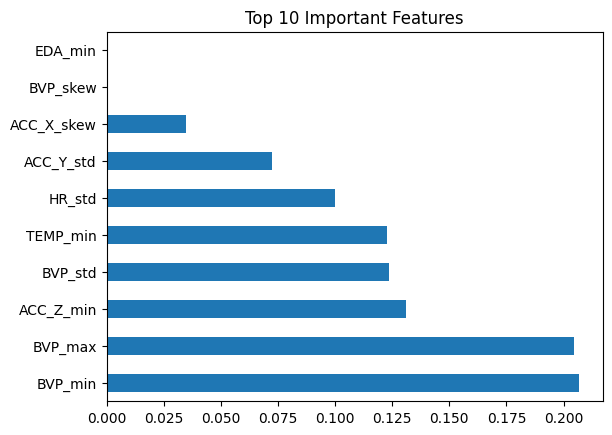

In [27]:
import matplotlib.pyplot as plt

# ดูว่า Sensor ตัวไหนมีผลต่อการทายมากที่สุด
importances = pd.Series(model_xgb.feature_importances_, index=X.columns)
importances.nlargest(10).plot(kind='barh')
plt.title("Top 10 Important Features")
plt.show()